## Dataset Description

The Student Performance Prediction project uses the `StudentPerformanceFactors.csv` dataset. It contains 6,607 records and 20 columns related to students' study habits, attendance, previous academic scores, family background, and school environment.

The dataset includes numerical features such as Hours Studied, Attendance, Sleep Hours, Previous Scores, Tutoring Sessions, and Physical Activity. It also includes categorical features such as Motivation Level, Parental Involvement, School Type, Internet Access, Gender, and Parental Education Level.

The `Exam_Score` column is the target variable used to represent student examination performance.

## Data Preprocessing

The initial dataset contained 235 missing values across three columns: Teacher_Quality (78), Parental_Education_Level (90), and Distance_from_Home (67). These missing categorical values were filled using the mode of their respective columns. No duplicate rows were found.

After preprocessing, the dataset contained 6,607 rows and 20 columns, with no remaining missing values.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:

import pandas as pd

df = pd.read_csv('/content/StudentPerformanceFactors.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (6607, 20)

First 5 Rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



Column Names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Missing Values:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate Rows: 0


In [3]:

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Fill missing categorical values with the mode
categorical_cols = [
    'Teacher_Quality',
    'Parental_Education_Level',
    'Distance_from_Home'
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())


Missing values before cleaning:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Missing values after cleaning:
Series([], dtype: int64)

Dataset Shape: (6607, 20)
Duplicate Rows: 0


In [4]:

# Save the cleaned dataset
df.to_csv('/content/StudentPerformanceFactors_Cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Remaining missing values:", df.isnull().sum().sum())


Cleaned dataset saved successfully!
Rows: 6607
Columns: 20
Remaining missing values: 0


In [5]:

from google.colab import files

files.download('/content/StudentPerformanceFactors_Cleaned.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

# Basic statistical summary
display(df.describe())

# Exam score distribution
print("Exam Score Statistics:")
print(df['Exam_Score'].describe())

# Correlation of numerical columns with Exam Score
print("\nCorrelation with Exam Score:")
print(
    df.corr(numeric_only=True)['Exam_Score']
      .sort_values(ascending=False)
)


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


Exam Score Statistics:
count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

Correlation with Exam Score:
Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64


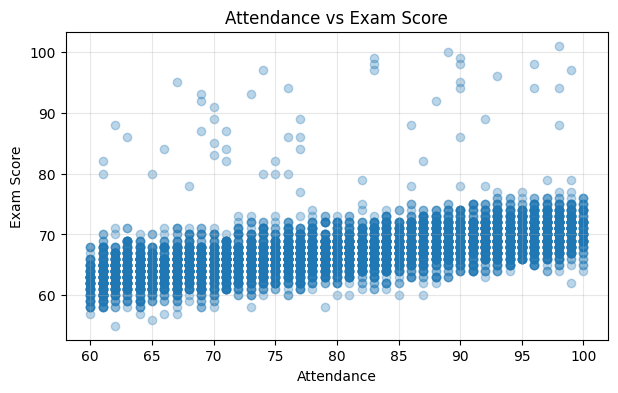

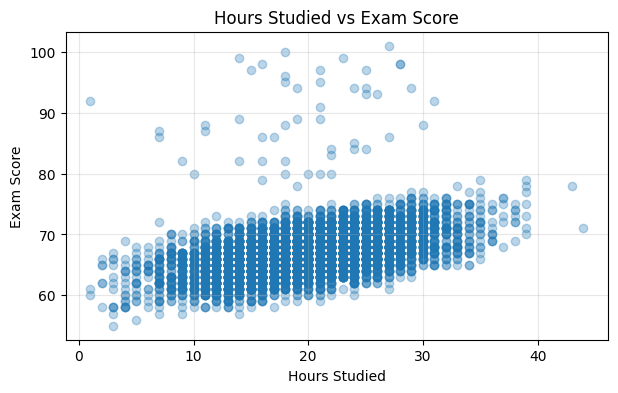

In [7]:

import matplotlib.pyplot as plt

# Graph 1: Attendance vs Exam Score
plt.figure(figsize=(7, 4))
plt.scatter(df['Attendance'], df['Exam_Score'], alpha=0.3)
plt.xlabel('Attendance')
plt.ylabel('Exam Score')
plt.title('Attendance vs Exam Score')
plt.grid(True, alpha=0.3)
plt.show()

# Graph 2: Hours Studied vs Exam Score
plt.figure(figsize=(7, 4))
plt.scatter(df['Hours_Studied'], df['Exam_Score'], alpha=0.3)
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Hours Studied vs Exam Score')
plt.grid(True, alpha=0.3)
plt.show()


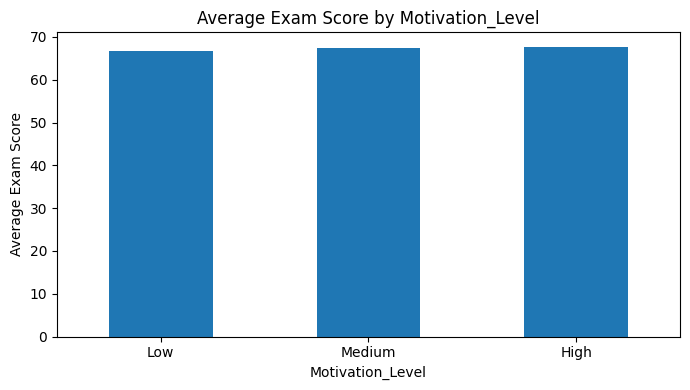

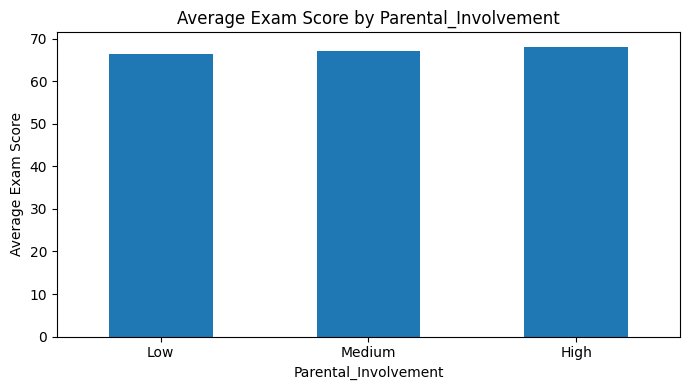

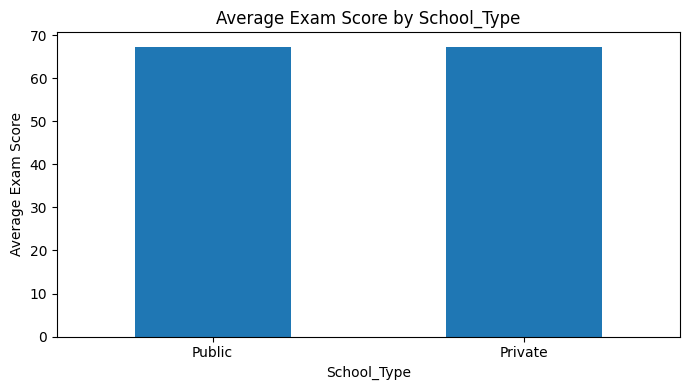

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

categorical_cols = [
    'Motivation_Level',
    'Parental_Involvement',
    'School_Type'
]

for col in categorical_cols:
    avg_scores = df.groupby(col)['Exam_Score'].mean().sort_values()

    plt.figure(figsize=(7, 4))
    avg_scores.plot(kind='bar')
    plt.title(f'Average Exam Score by {col}')
    plt.xlabel(col)
    plt.ylabel('Average Exam Score')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


In [11]:

from google.colab import files

files.download('/content/StudentPerformanceFactors_Cleaned.csv')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the dataset and identify relationships between student-related factors and exam scores. The analysis included statistical summaries, correlation analysis, and visualizations.

The results showed that Attendance had a positive correlation of approximately 0.58 with Exam_Score, while Hours_Studied had a positive correlation of approximately 0.45. These findings indicate that attendance and study hours were positively associated with exam performance in this dataset.